<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Ethics and the Bias-Variance Trade off

#Core Question 4

In [ ]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load homicide reports from Kaggle
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "murderaccountability/homicide-reports",
    "database.csv"
)

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())


Accuracy: 0.709
Precision: 0.714
Recall: 0.976
F1 Score: 0.825

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.08      0.14     38056
           1       0.71      0.98      0.82     89635

    accuracy                           0.71    127691
   macro avg       0.65      0.53      0.48    127691
weighted avg       0.68      0.71      0.62    127691



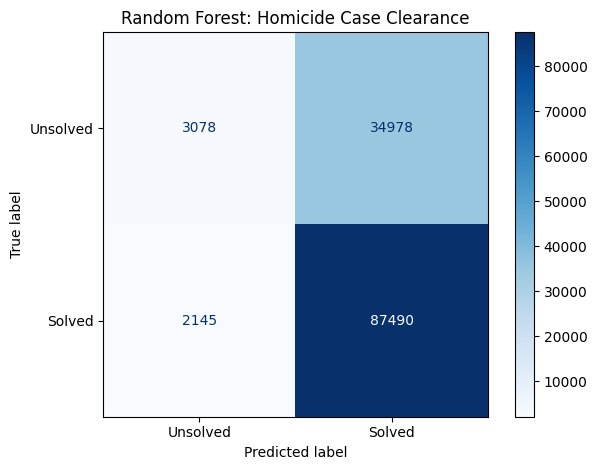


Predicted case status: Solved
Estimated probability of being recorded as solved: 62.53%


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    classification_report
)

# Use the previously loaded homicide dataset (df)

# Select information potentially available at the start
# of an investigation, excluding location and perpetrator data.
features = [
    "Year",
    "Victim Age",
    "Victim Sex",
    "Weapon",
    "Crime Type"
]

# Retain records with a known case status
data = df[df["Crime Solved"].isin(["Yes", "No"])].copy()

# Convert age to numeric, handling invalid values
data["Victim Age"] = pd.to_numeric(
    data["Victim Age"], errors="coerce"
)

# Encode target: 1 = solved, 0 = unsolved
X = data[features]
y = (data["Crime Solved"] == "Yes").astype(int)

# Define numeric and categorical columns
numeric_features = ["Year", "Victim Age"]
categorical_features = [
    "Victim Sex", "Weapon", "Crime Type"
]

# Preprocess the features
preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"),
     numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]), categorical_features)
])

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build the Random Forest classification model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

# Predict outcomes on the test set
y_pred = model.predict(X_test)

# Evaluate classification performance
print("Accuracy:", round(
    accuracy_score(y_test, y_pred), 3
))
print("Precision:", round(
    precision_score(y_test, y_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, y_pred, zero_division=0), 3
))
print("F1 Score:", round(
    f1_score(y_test, y_pred, zero_division=0), 3
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Visualize the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Unsolved", "Solved"],
    cmap="Blues"
)

plt.title("Random Forest: Homicide Case Clearance")
plt.tight_layout()
plt.show()

# Example prediction for a hypothetical historical case
sample_case = pd.DataFrame([{
    "Year": 2010,
    "Victim Age": 35,
    "Victim Sex": "Male",
    "Weapon": "Handgun",
    "Crime Type": "Murder or Manslaughter"
}])

prediction = model.predict(sample_case)[0]
probability = model.predict_proba(sample_case)[0]

print("\nPredicted case status:",
      "Solved" if prediction == 1 else "Unsolved")

print("Estimated probability of being recorded as solved:",
      f"{probability[1]:.2%}")


#Extension Question

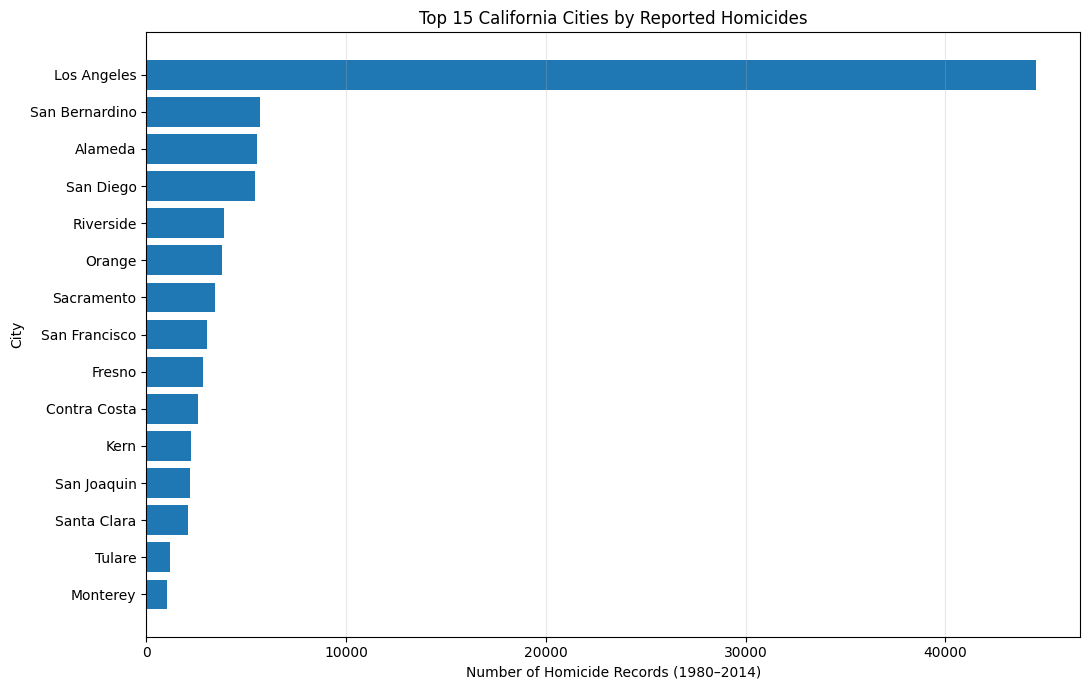

City
Los Angeles       44511
San Bernardino     5717
Alameda            5551
San Diego          5456
Riverside          3893
Orange             3812
Sacramento         3416
San Francisco      3016
Fresno             2844
Contra Costa       2569
Kern               2250
San Joaquin        2196
Santa Clara        2076
Tulare             1201
Monterey           1057
Name: Record ID, dtype: int64


In [ ]:
# code generated using ChatGPT and Claude and I made my own edits
import pandas as pd
import matplotlib.pyplot as plt

# Filter homicide reports for California
california = df[
    df["State"].str.strip().str.lower() == "california"
].copy()

# Count homicide records for each city
city_counts = (
    california.groupby("City")["Record ID"]
    .count()
    .sort_values(ascending=False)
)

# Select the 15 cities with the most recorded homicides
top_cities = city_counts.head(15)

# Visualize homicide records by city
plt.figure(figsize=(11, 7))

plt.barh(
    top_cities.index[::-1],
    top_cities.values[::-1]
)

plt.xlabel("Number of Homicide Records (1980–2014)")
plt.ylabel("City")
plt.title("Top 15 California Cities by Reported Homicides")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Display the numerical results
print(top_cities)
